In [32]:
import numpy as np
import pandas as pd   

df = pd.read_csv("cancer_immunotherapy.csv")


In [33]:
df.head(2)

,PatientID,Age,Gender,TumorType,ImmunotherapyType,BiomarkerExpressionLevel,TreatmentResponse,SurvivalInMonths,Relapse,MutationCount
0,P001,45,F,Lung,PD-1 Inhibitor,High,Partial Response,12,Yes,150
1,P002,67,M,Breast,CTLA-4 Inhibitor,Low,Stable Disease,20,No,320


In [34]:
fahh = df.shape
print(fahh[:])

(10, 10)


In [35]:
df.info()
df.dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   PatientID                 10 non-null     object
 1   Age                       10 non-null     int64 
 2   Gender                    10 non-null     object
 3   TumorType                 10 non-null     object
 4   ImmunotherapyType         10 non-null     object
 5   BiomarkerExpressionLevel  10 non-null     object
 6   TreatmentResponse         10 non-null     object
 7   SurvivalInMonths          10 non-null     int64 
 8   Relapse                   10 non-null     object
 9   MutationCount             10 non-null     int64 
dtypes: int64(3), object(7)
memory usage: 932.0+ bytes


PatientID                   object
Age                          int64
Gender                      object
TumorType                   object
ImmunotherapyType           object
BiomarkerExpressionLevel    object
TreatmentResponse           object
SurvivalInMonths             int64
Relapse                     object
MutationCount                int64
dtype: object

In [36]:
df.describe(include = "all")

,PatientID,Age,Gender,TumorType,ImmunotherapyType,BiomarkerExpressionLevel,TreatmentResponse,SurvivalInMonths,Relapse,MutationCount
count,10,10.000000,10,10,10,10,10,10.000000,10,10.000000
unique,10,NaN,2,3,3,3,4,NaN,2,NaN
top,P001,NaN,F,Lung,PD-1 Inhibitor,High,Partial Response,NaN,Yes,NaN
freq,1,NaN,6,4,4,4,3,NaN,5,NaN
mean,NaN,56.400000,NaN,NaN,NaN,NaN,NaN,21.800000,NaN,215.000000
std,NaN,12.231108,NaN,NaN,NaN,NaN,NaN,12.839176,NaN,107.935166
min,NaN,38.000000,NaN,NaN,NaN,NaN,NaN,8.000000,NaN,50.000000
25%,NaN,46.250000,NaN,NaN,NaN,NaN,NaN,12.500000,NaN,157.500000
50%,NaN,57.500000,NaN,NaN,NaN,NaN,NaN,18.000000,NaN,210.000000
75%,NaN,66.500000,NaN,NaN,NaN,NaN,NaN,28.500000,NaN,287.500000


In [37]:
df.columns

for i in range(len(df.columns)): print(f"column {i+1}: {df.columns[i]}")

column 1: PatientID
column 2: Age
column 3: Gender
column 4: TumorType
column 5: ImmunotherapyType
column 6: BiomarkerExpressionLevel
column 7: TreatmentResponse
column 8: SurvivalInMonths
column 9: Relapse
column 10: MutationCount


In [38]:
# no of columns
len(df)

10

In [39]:
df[df['Age'] > 50]['TumorType']

1      Breast
2    Melanoma
3        Lung
5    Melanoma
6      Breast
8        Lung
Name: TumorType, dtype: object

In [40]:
yo = df['TumorType'].value_counts()

In [41]:
df.groupby('TumorType')['SurvivalInMonths'].mean()

TumorType
Breast      14.666667
Lung        15.000000
Melanoma    38.000000
Name: SurvivalInMonths, dtype: float64

In [42]:
#sort_values
df['Age'].sort_values(ascending = False)

6    72
3    70
1    67
8    65
5    60
2    55
7    50
0    45
9    42
4    38
Name: Age, dtype: int64

In [43]:
#lessthan
df[df['Age'] < 50]['PatientID'].sort_values(ascending = True)

0    P001
4    P005
9    P010
Name: PatientID, dtype: object

<Axes: xlabel='TumorType'>

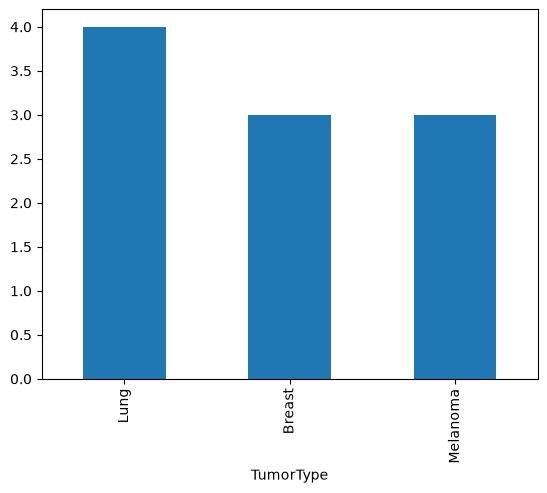

In [44]:
anew = df['TumorType'].value_counts()
anew.plot(kind = 'bar')




In [45]:
df['ImmunotherapyType'].value_counts()

ImmunotherapyType
PD-1 Inhibitor      4
CTLA-4 Inhibitor    3
PD-L1 Inhibitor     3
Name: count, dtype: int64

TumorType
Lung        4
Breast      3
Melanoma    3
Name: count, dtype: int64


<Axes: xlabel='TumorType'>

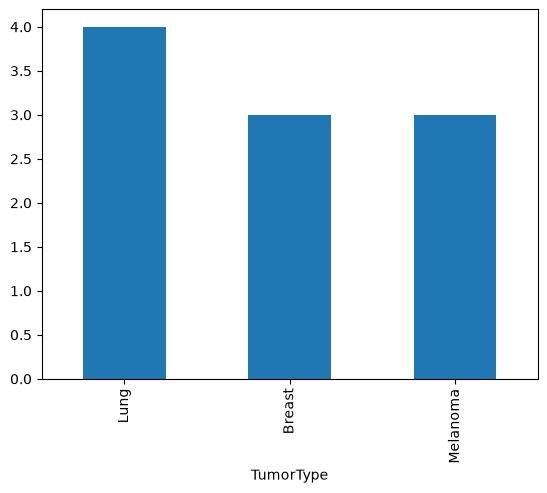

In [46]:
tu_count = df.groupby("TumorType")["MutationCount"].sum()
yo = df['TumorType'].value_counts()

print(yo)
yo.plot(kind = 'bar')





In [47]:
df.groupby("TumorType")['MutationCount'].mean()

TumorType
Breast      340.0
Lung        170.0
Melanoma    150.0
Name: MutationCount, dtype: float64

In [48]:
df[['ImmunotherapyType','TreatmentResponse']]

,ImmunotherapyType,TreatmentResponse
0,PD-1 Inhibitor,Partial Response
1,CTLA-4 Inhibitor,Stable Disease
2,PD-L1 Inhibitor,Complete Response
3,PD-1 Inhibitor,Progressive Disease
4,CTLA-4 Inhibitor,Partial Response
5,PD-L1 Inhibitor,Stable Disease
6,PD-1 Inhibitor,Progressive Disease
7,CTLA-4 Inhibitor,Complete Response
8,PD-L1 Inhibitor,Stable Disease
9,PD-1 Inhibitor,Partial Response


In [49]:
pd.crosstab(
    df['ImmunotherapyType'],
    df['TreatmentResponse']
)

TreatmentResponse,Complete Response,Partial Response,Progressive Disease,Stable Disease
ImmunotherapyType,,,,
CTLA-4 Inhibitor,1,1,0,1
PD-1 Inhibitor,0,2,2,0
PD-L1 Inhibitor,1,0,0,2


In [50]:
df[['BiomarkerExpressionLevel','TreatmentResponse' ]]

,BiomarkerExpressionLevel,TreatmentResponse
0,High,Partial Response
1,Low,Stable Disease
2,Medium,Complete Response
3,High,Progressive Disease
4,Medium,Partial Response
5,High,Stable Disease
6,Low,Progressive Disease
7,Medium,Complete Response
8,High,Stable Disease
9,Low,Partial Response


In [51]:
pd.crosstab(
  df['BiomarkerExpressionLevel'],
  df['TreatmentResponse']  
)

TreatmentResponse,Complete Response,Partial Response,Progressive Disease,Stable Disease
BiomarkerExpressionLevel,,,,
High,0,1,1,2
Low,0,1,1,1
Medium,2,1,0,0


In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

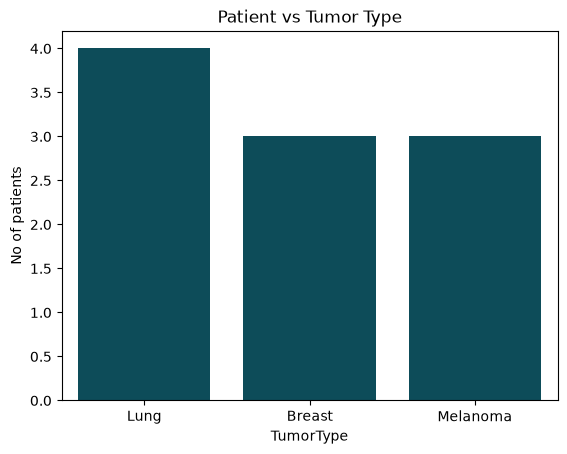

In [53]:
#patients vs cancer type
sns.countplot(data = df, x = 'TumorType', color='#005566')
# tcount = df['TumorType'].value_counts()
# tcount.plot(kind="bar")

plt.title("Patient vs Tumor Type")
plt.xlabel("TumorType")
plt.ylabel('No of patients')
plt.show()

C:\Users\chath\AppData\Local\Temp\ipykernel_33304\1115513225.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


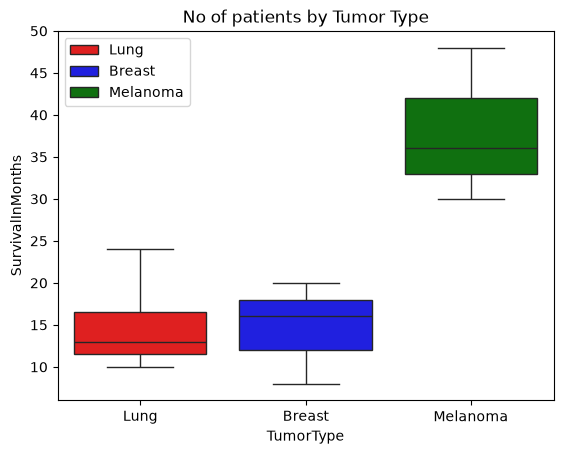

In [59]:
#box plot - survival by tumor type
sns.boxplot(
    data = df,
    x = "TumorType",
    y = "SurvivalInMonths",
    palette = ['red', 'blue', 'green']
)

plt.title("No of patients by Tumor Type")
plt.legend(df['TumorType'])
plt.show()

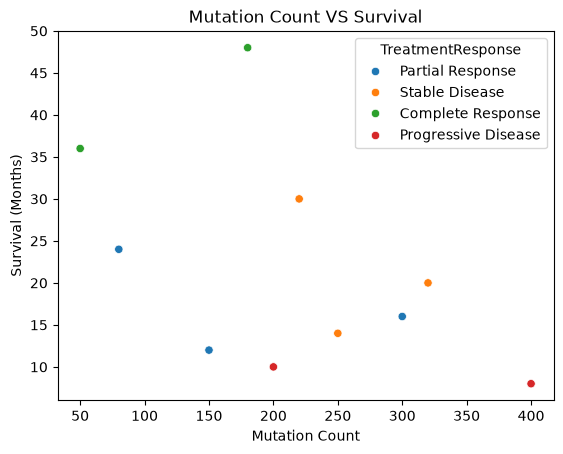

In [55]:
#Scatter Plot

sns.scatterplot(
    data=df,
    x="MutationCount",
    y="SurvivalInMonths",
    hue="TreatmentResponse"
)

plt.title("Mutation Count VS Survival")
plt.xlabel("Mutation Count")
plt.ylabel("Survival (Months)")
# plt.legend('TreatmentResponse')
plt.show()

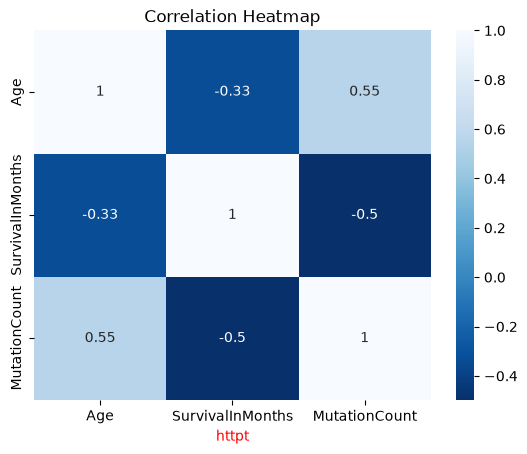

In [62]:
#heatmap

numeric_df = df[
    ["Age", "SurvivalInMonths", "MutationCount"]
]

corr = numeric_df.corr()
sns.heatmap(
    corr,
    annot = True,
    cmap = "Blues_r" #'viridis', 'plasma', 'inferno', 'coolwarm', 'YlGn'
)

plt.title("Correlation Heatmap")
plt.xlabel("httpt", color = 'red')
plt.show()

In [57]:
corr2 = corr.copy()

for i in range(len(corr2)):
    corr2.iloc[i, i] = 0
    
print("max correlation: ", corr2.stack().idxmax())
print("max correlation: ", corr2.stack().max())

max correlation:  ('Age', 'MutationCount')
max correlation:  0.5529604891938789
